In [1]:
import easygems.healpix as egh
import xarray as xr
from pathlib import Path
import pandas as pd
import intake
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
from functools import partial
from matplotlib import cm
from dask.distributed import Client
from sea_breeze import sea_breeze_funcs
import glob

In [2]:
#Start a dask distributed client to enable parallel computing

Client()

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 7
Total threads: 14,Total memory: 63.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41567,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38145,Total threads: 2
Dashboard: /proxy/45941/status,Memory: 9.00 GiB
Nanny: tcp://127.0.0.1:37213,


2025-07-15 09:19:09,559 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 3ad24d237755674984f61cb0ba58bcba initialized by task ('rechunk-merge-rechunk-transfer-49e6184fb4d51f9b930d41d6c994afa3', 0, 22, 13, 33) executed on worker tcp://127.0.0.1:41313
2025-07-15 09:19:09,902 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle c58c2d42fb97bd65453037f5f52b470a initialized by task ('rechunk-merge-rechunk-transfer-49e6184fb4d51f9b930d41d6c994afa3', 0, 20, 14, 30) executed on worker tcp://127.0.0.1:41873
2025-07-15 09:19:50,440 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle d33e9dfd6ec3a427fd154a47f2222ba4 initialized by task ('rechunk-merge-rechunk-transfer-cbcc42cbe784e4258d151deebed1d03b', 0, 22, 9, 33) executed on worker tcp://127.0.0.1:41313
2025-07-15 09:19:58,319 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 3ad24d237755674984f61cb0ba58bcba deactivated due to stimulus 'task-finished-1752535198.317354'
2025-07-15 09:19:58,726 - distributed.s

In [3]:
#Load the UM land mask file
um_land = "/g/data/gb02/ab4502/hk25_AusNode_coastal/sftlf_um_z8.zarr" #PT1H is hourly data
um_land_mask = xr.open_zarr(um_land)

In [4]:
#Load the ERA5 land mask file
era5_land = "/g/data/rt52/era5/single-levels/reanalysis/lsm/1940/lsm_era5_oper_sfc_19400101-19400131.nc" #PT1H is hourly data
era5_land_mask = xr.open_dataset(era5_land).isel(time=0)

In [5]:
#Load the UM u and v wind data
data_2d_z2 = "/g/data/qx55/uk_node/glm.n2560_RAL3p3/data.healpix.PT1H.z8.zarr" #PT1H is hourly data
ds = xr.open_zarr(data_2d_z2,chunks={}).chunk({"time":-1,"cell":1000})
ds = ds.pipe(partial(egh.attach_coords))
ds = ds.sel(time=slice("2020-04-01","2021-04-01"))


In [6]:
#Calculate surface wind speed from the UM
ws = (ds.uas**2 + ds.vas**2)**0.5

In [7]:
#Calculate hourly average composites
ws_hour = ws.groupby("time.hour").mean().persist()

In [8]:
#Load ERA5 u and v wind data for the same period
file_list1 = sorted(
    glob.glob("/g/data/rt52/era5/single-levels/reanalysis/10u/2020/*.nc") +
    glob.glob("/g/data/rt52/era5/single-levels/reanalysis/10u/2021/*.nc")
)
file_list2 = sorted(
    glob.glob("/g/data/rt52/era5/single-levels/reanalysis/10v/2020/*.nc") +
    glob.glob("/g/data/rt52/era5/single-levels/reanalysis/10v/2021/*.nc")
)
era5_u10 = xr.open_mfdataset(file_list1, combine='by_coords').sel(time=slice("2020-04-01","2021-04-01")).chunk({"time":1000})
era5_v10 = xr.open_mfdataset(file_list2, combine='by_coords').sel(time=slice("2020-04-01","2021-04-01")).chunk({"time":1000})

In [9]:
#Calculate surface wind speed
era5_ws = (era5_u10.u10**2 + era5_v10.v10**2)**0.5

In [10]:
#Calculate hourly average composite
ws_hour_era5 = era5_ws.groupby("time.hour").mean().persist()

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.06/lib/python3.11/site-packages/distributed/client.py:3363: UserWarning: Sending large graph of size 13.18 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [13]:
#Plot the amplitude of the diurnal cycle in wind speed for the UM

def plot_global(da,cmap="viridis",vmin=None,vmax=None):
    projection=ccrs.PlateCarree(central_longitude=0.0)
    ax = egh.create_geoaxis(add_coastlines=True,projection=projection)
    im = egh.healpix_show(da, ax=ax, add_coastlines=True, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.gridlines(draw_labels=True)
    fig=ax.get_figure()
    fig.colorbar(im,orientation='horizontal')


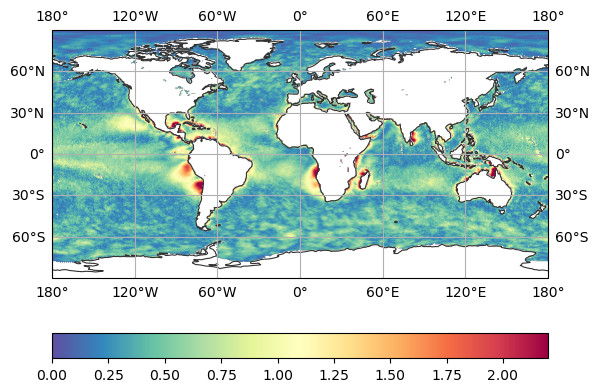

In [28]:
plot_global(
    xr.where(
        um_land_mask.sftlf,
        np.nan,
        (ws_hour.max("hour") - ws_hour.min("hour"))
    ),
    cmap="Spectral_r",
    vmin=0,
    vmax=2.2)

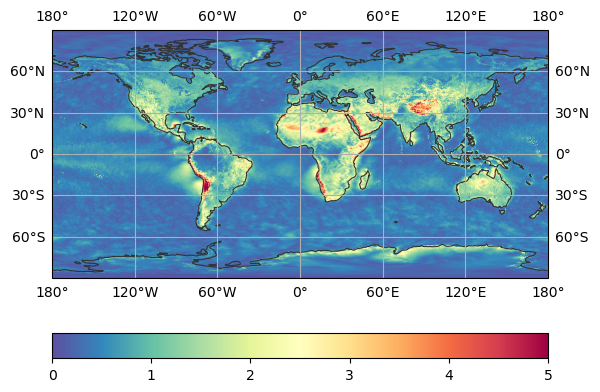

In [29]:
plot_global(
    (ws_hour.max("hour") - ws_hour.min("hour")),
    cmap="Spectral_r",
    vmin=0,
    vmax=5)

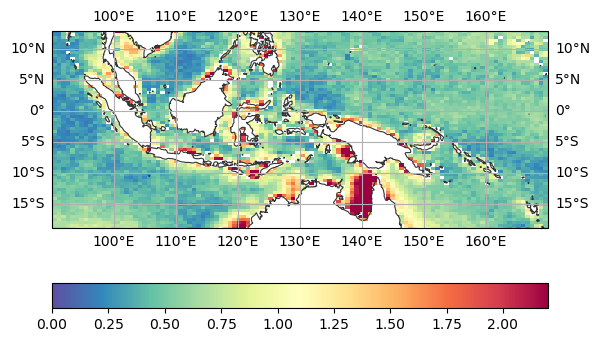

In [20]:
plot_global(
    xr.where(
        um_land_mask.sftlf,
        np.nan,
        (ws_hour.max("hour") - ws_hour.min("hour"))
    ),
    cmap="Spectral_r",
    vmin=0,
    vmax=2.2
)

plt.gca().set_extent([90, 170, -15, 10])

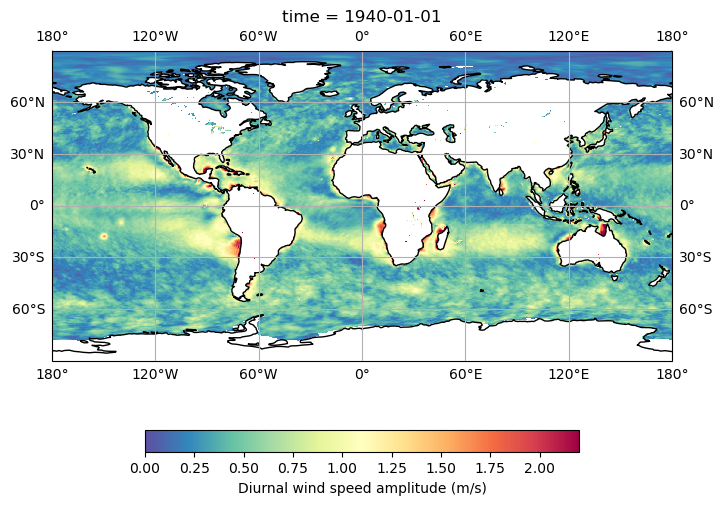

In [17]:
#Plot the amplitude of the diurnal cycle in wind speed for ERA5

fig, ax = plt.subplots(
    figsize=(8, 6),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)}
)
p=xr.where(
    era5_land_mask.lsm > 0.5,
    np.nan,
    (ws_hour_era5.max("hour") - ws_hour_era5.min("hour") )
).plot(vmin=0,vmax=2.2,cmap="Spectral_r",add_colorbar=False)
ax.coastlines()
fig.colorbar(p, ax=ax, orientation='horizontal', label= "Diurnal wind speed amplitude (m/s)",shrink=0.7)
ax.gridlines(draw_labels=True)

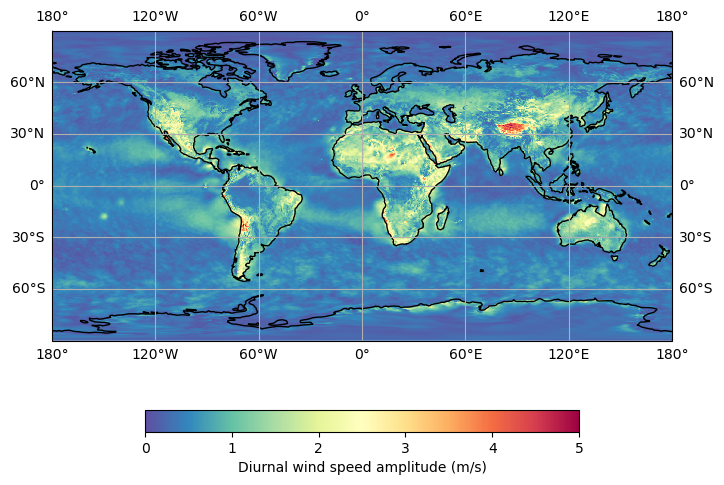

In [30]:
#Plot the amplitude of the diurnal cycle in wind speed for ERA5

fig, ax = plt.subplots(
    figsize=(8, 6),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)}
)
p=(ws_hour_era5.max("hour") - ws_hour_era5.min("hour") ).plot(vmin=0,vmax=5,cmap="Spectral_r",add_colorbar=False)
ax.coastlines()
fig.colorbar(p, ax=ax, orientation='horizontal', label= "Diurnal wind speed amplitude (m/s)",shrink=0.7)
ax.gridlines(draw_labels=True)

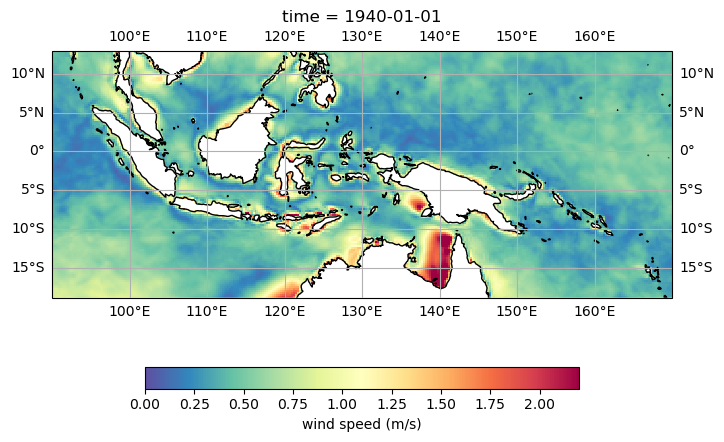

In [19]:
#Plot the amplitude of the diurnal cycle in wind speed for ERA5

fig, ax = plt.subplots(
    figsize=(8, 6),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)}
)
p=xr.where(
    era5_land_mask.lsm > 0.5,
    np.nan,
    (ws_hour_era5.max("hour") - ws_hour_era5.min("hour") )
).plot(vmin=0,vmax=2.2,cmap="Spectral_r",add_colorbar=False)
ax.coastlines()
fig.colorbar(p, ax=ax, orientation='horizontal', label= "wind speed (m/s)",shrink=0.7)
ax.gridlines(draw_labels=True)
plt.gca().set_extent([90, 170, -15, 10])

In [23]:
#Load in coastline angle and distance info
angle_ds = xr.open_dataset("/g/data/gb02/ab4502/hk25_AusNode_coastal/um_angles_z8.zarr/",engine="zarr")
angle_ds_era5 = xr.open_dataset("/g/data/gb02/ab4502/hk25_AusNode_coastal/era5_global_angles.nc")

In [24]:
#Calculate the diurnal amplitude in wind speed and load into memory
diurnal_amp = (ws_hour.max("hour") - ws_hour.min("hour")).persist()
diurnal_amp_era5 = (ws_hour_era5.max("hour") - ws_hour_era5.min("hour")).persist()

In [25]:
#Load in the min dist to coast data, and flip the onshore sign
min_coast_dist = xr.where(um_land_mask.sftlf,-angle_ds.min_coast_dist,angle_ds.min_coast_dist)
min_coast_dist_era5 = xr.where(
    era5_land_mask.reindex(latitude=list(reversed(era5_land_mask.latitude))).lsm.rename({"latitude":"lat","longitude":"lon"})>0.5,
    -angle_ds_era5.min_coast_dist,
    angle_ds_era5.min_coast_dist)

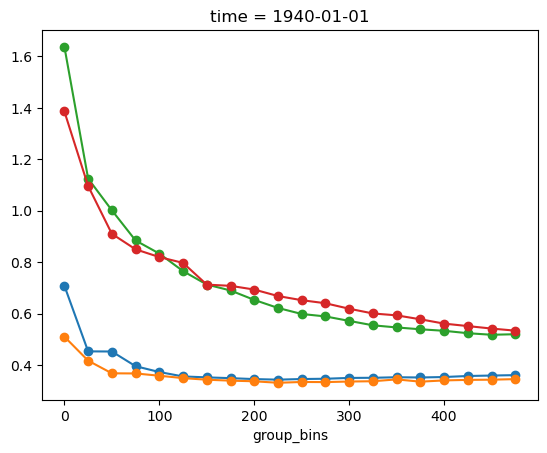

In [54]:
#Group the diurnal wind speed amplitude into distances from coast, and plot

bins = np.arange(-12.5,512.5,25)
bin_centers = np.arange(0,500,25)

# bins = np.arange(-512.5,512.5,50)
# bin_centers = np.arange(-500,500,50)

temp_min_coast_dist = min_coast_dist.sel(cell=np.abs(diurnal_amp.lat)>=30)
temp_min_coast_dist_era5 = min_coast_dist_era5.sel(lat=np.abs(min_coast_dist_era5.lat)>=30)

temp_diurnal_amp = diurnal_amp.sel(cell=np.abs(diurnal_amp.lat)>=30)
temp_diurnal_amp_era5 = diurnal_amp_era5.sel(latitude=np.abs(diurnal_amp_era5.latitude)>=30)

diurnal_amp_group_mean = temp_diurnal_amp.groupby_bins(temp_min_coast_dist,bins).mean().persist().assign_coords({"group_bins":bin_centers})
diurnal_amp_group_era5_mean = temp_diurnal_amp_era5.reindex(latitude=list(reversed(temp_diurnal_amp_era5.latitude))).rename({"latitude":"lat","longitude":"lon"}).groupby_bins(
    temp_min_coast_dist_era5,bins).mean().persist().assign_coords({"group_bins":bin_centers})

diurnal_amp_group_mean.plot(marker="o")
diurnal_amp_group_era5_mean.plot(marker="o")







temp_min_coast_dist = min_coast_dist.sel(cell=np.abs(diurnal_amp.lat)<30)
temp_min_coast_dist_era5 = min_coast_dist_era5.sel(lat=np.abs(min_coast_dist_era5.lat)<30)

temp_diurnal_amp = diurnal_amp.sel(cell=np.abs(diurnal_amp.lat)<30)
temp_diurnal_amp_era5 = diurnal_amp_era5.sel(latitude=np.abs(diurnal_amp_era5.latitude)<30)

diurnal_amp_group_mean = temp_diurnal_amp.groupby_bins(temp_min_coast_dist,bins).mean().persist().assign_coords({"group_bins":bin_centers})
diurnal_amp_group_era5_mean = temp_diurnal_amp_era5.reindex(latitude=list(reversed(temp_diurnal_amp_era5.latitude))).rename({"latitude":"lat","longitude":"lon"}).groupby_bins(
    temp_min_coast_dist_era5,bins).mean().persist().assign_coords({"group_bins":bin_centers})

diurnal_amp_group_mean.plot(marker="o")
diurnal_amp_group_era5_mean.plot(marker="o")

In [194]:
#Do the same for different latitude bins for the UM

lat_bins = np.arange(-90,120,30)
lat_bin_centers = np.arange(-75,90,30)
bins = np.arange(-12.5,512.5,25)
bin_centers = np.arange(0,500,25)

out_ls = []
for i in range(len(lat_bins)-1):
    
    diurnal_amp_group_mean_temp = \
        xr.where((diurnal_amp.lat>=lat_bins[i]) & (diurnal_amp.lat<lat_bins[i+1]),
                 diurnal_amp,
                 np.nan)
    diurnal_amp_group_mean_temp = diurnal_amp_group_mean_temp.groupby_bins(min_coast_dist,bins).mean().persist().assign_coords({"group_bins":bin_centers})
    out_ls.append(diurnal_amp_group_mean_temp)

out = xr.concat(out_ls,"lat").assign_coords({"lat":lat_bin_centers})

In [195]:
#And for ERA5

out_ls_era5 = []
temp_diurnal_amp = diurnal_amp_era5.reindex(latitude=list(reversed(diurnal_amp_era5.latitude))).rename({"latitude":"lat","longitude":"lon"})
for i in range(len(lat_bins)-1):

    
    diurnal_amp_group_mean_temp = \
        xr.where((temp_diurnal_amp.lat>=lat_bins[i]) & (temp_diurnal_amp.lat<lat_bins[i+1]),
                 temp_diurnal_amp,
                 np.nan)
    diurnal_amp_group_mean_temp = diurnal_amp_group_mean_temp.groupby_bins(min_coast_dist_era5,bins).mean().persist().assign_coords({"group_bins":bin_centers})
    out_ls_era5.append(diurnal_amp_group_mean_temp)

out_era5 = xr.concat(out_ls_era5,"lat").assign_coords({"lat":lat_bin_centers})

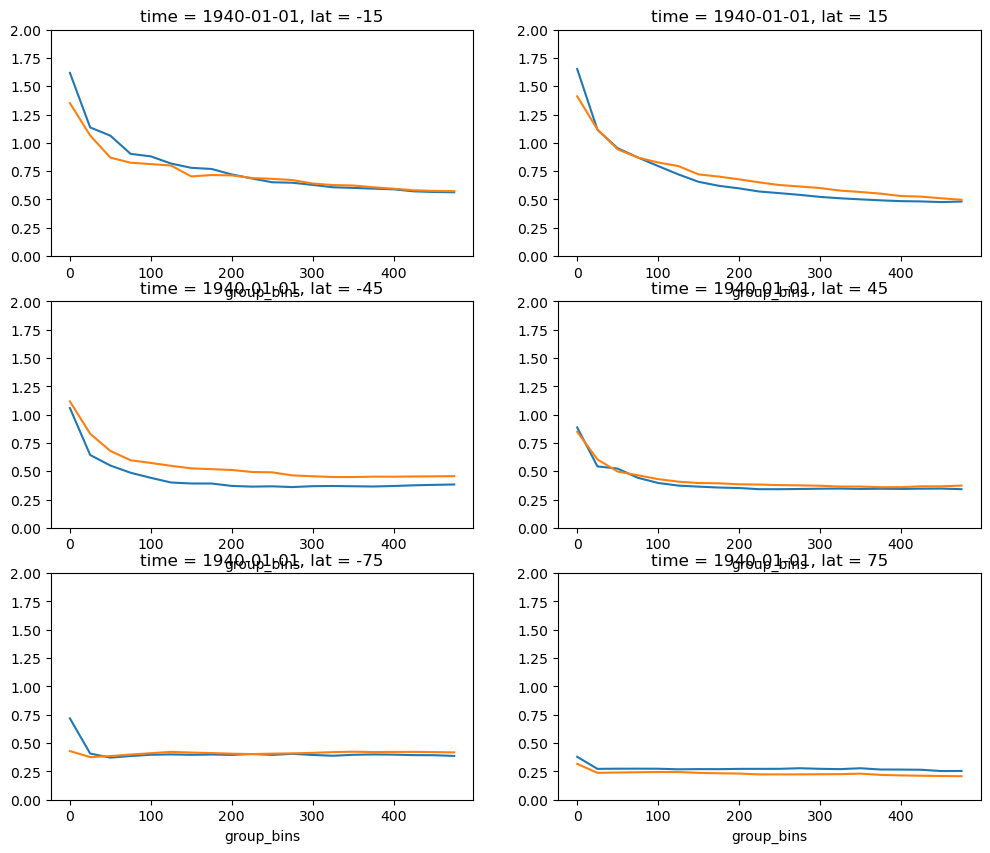

In [196]:
#Plot the binned diurnal wind speed amplitude for different latitude bands, for UM and ERA5

plt.figure(figsize=[12,10])
cnt=1
for i in [2,3,1,4,0,5]:
    plt.subplot(3,2,cnt)
    out.isel(lat=i).plot(label="["+str(lat_bins[i])+", "+str(lat_bins[i+1])+"]",marker="none",color="tab:blue")
    out_era5.isel(lat=i).plot(label="["+str(lat_bins[i])+", "+str(lat_bins[i+1])+"]",marker="none",color="tab:orange")
    plt.ylim([0,2])
    cnt=cnt+1


In [9]:
#Calculate the local solar time offset for all longitudes from the UM

import pandas as pd
import datetime as dt
import tqdm


lst_da_ls = []
for h in tqdm.tqdm(np.arange(0,24)):
    lst = [dt.datetime(2000,1,1,h) + dt.timedelta(hours=l / 180 * 12) for l in ws.lon.values]
    lst_arr = np.array(pd.to_datetime(lst).round("h").hour)
    lst_da = xr.DataArray(data=lst_arr,dims=["cell"],coords={"lat":ws.lat,"lon":ws.lon})
    lst_da_ls.append(lst_da)

lst_da = xr.concat(lst_da_ls,dim="hour")
lst_da = lst_da.assign_coords({"hour":np.arange(0,24)})

100%|██████████| 24/24 [01:23<00:00,  3.49s/it]


In [10]:
#Convert the hourly composited wind speeds to local solar time
ws_hour_lst = xr.concat([ws_hour.where(lst_da==h,drop=True).mean("hour") for h in np.arange(24)],dim="hour").persist()

NameError: name 'ws_hour' is not defined

In [15]:
#Calculate the mean wind speed for the period
ws_mean = ws.mean("time").persist()

In [16]:
#Calculate the wind speed perturbation from the local solar time array
ws_hour_lst_pert = (ws_hour_lst - ws_mean).persist()

In [17]:
#Bin the perturbations into distance from the coast
bins = np.arange(-512.5,512.5,25)
ws_hour_lst_pert_group = ws_hour_lst_pert.groupby_bins(min_coast_dist,bins=bins).mean().persist()

NameError: name 'min_coast_dist' is not defined

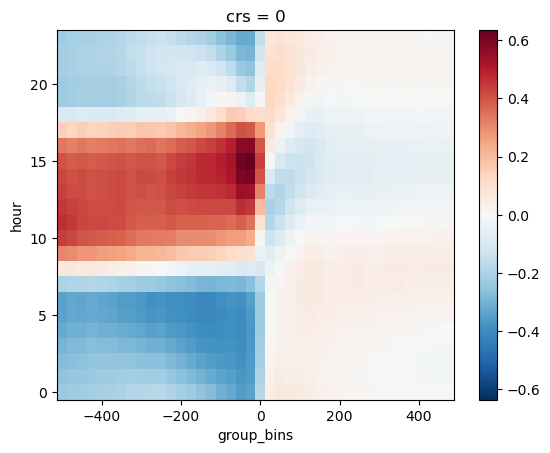

In [59]:
ws_hour_lst_pert_group.plot()

In [11]:
#Calculate the cross-shore wind component (vprime)
uprime, vprime = sea_breeze_funcs.rotate_wind(ds.uas,ds.vas,angle_ds.angle_interp)

In [12]:
#Group vprime by hour of the day
vprime_hour = vprime.groupby("time.hour").mean().persist()

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.06/lib/python3.11/site-packages/distributed/client.py:3363: UserWarning: Sending large graph of size 16.69 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [13]:
#Convert the hourly vprime composite to local solar time (LST) using the lst_da array
vprime_hour_lst = xr.concat([vprime_hour.where(lst_da==h,drop=True).mean("hour") for h in np.arange(24)],dim="hour").persist()

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.06/lib/python3.11/site-packages/distributed/client.py:3363: UserWarning: Sending large graph of size 473.00 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [ ]:
#Calculate the mean vprime and vprime perturbation
vprime_mean = vprime.mean("time").persist()

In [22]:
vprime_hour_lst_pert = (vprime_hour_lst - vprime_mean).persist()

In [23]:
#Bin the perturbations into distance from the coast
bins = np.arange(-512.5,512.5,25)
vprime_hour_lst_pert_group = vprime_hour_lst_pert.groupby_bins(min_coast_dist,bins=bins).mean().persist()

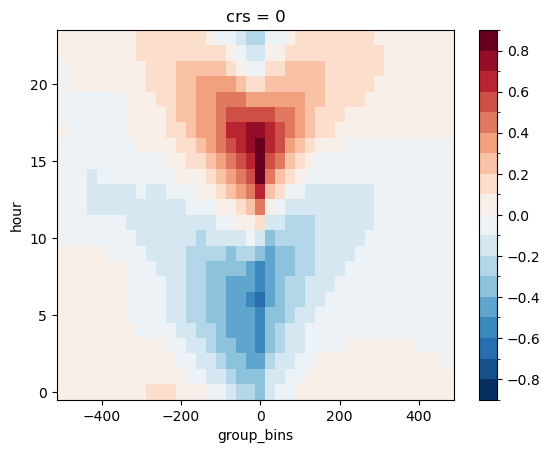

In [28]:
vprime_hour_lst_pert_group.plot(levels=21)